# 06 — Deployment Demo

This notebook shows how the models from **04 — Modeling**, evaluated in **05 — Evaluation**, could be used by a maintenance planner in the simulated scenario from **01 — Business Understanding**.

**Demo flow:** select an engine → prepare its sensor features → show the predicted remaining useful life (RUL) → show unusual sensor behaviour **separately** → rank the fleet for inspection.

What this notebook does **not** do:

- It does not train, tune or re-select any model. It only loads the saved files in `04_modeling/models/`.
- It does not make automatic maintenance decisions. 05 — Evaluation concluded that the model supports a *controlled, simulation-based demonstration with human review*, not autonomous decisions.

All data preparation and prediction code lives in `06_deployment/pm_deployment.py`. The Streamlit app and the tests import the same module, so every entry point prepares data in exactly the same way as 04 — Modeling.

## 1. Setup

Install the pinned versions first (see `06_deployment/README.md`). The saved models must be loaded with **scikit-learn 1.6.1** and **XGBoost 3.4.1**. The cell below reports any version difference.

In [1]:
import sys
from pathlib import Path

current = Path.cwd().resolve()
if current.name == "notebooks" and current.parent.name == "06_deployment":
    DEPLOY_DIR = current.parent
elif (current / "06_deployment").is_dir():
    DEPLOY_DIR = current / "06_deployment"
elif (current / "pm_deployment.py").is_file():
    DEPLOY_DIR = current
else:
    raise RuntimeError(f"Open this notebook from the repository or 06_deployment/notebooks: {current}")
sys.path.insert(0, str(DEPLOY_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm_deployment as pm

print("Repository:", pm.REPO_DIR)
problems = pm.check_versions()
print("\n".join(problems) if problems else "Library versions match the saved models.")

Repository: /content/repo


Library versions match the saved models.


## 2. Load the saved models

Three bundles from 04 — Modeling. Each bundle stores the estimator together with its ordered feature list, so the demo never guesses column names.

| Bundle | Role in the demo |
|---|---|
| `selected_model.joblib` | XGBoost, the selected RUL model |
| `baseline_model.joblib` | Linear Regression, shown only for comparison |
| `anomaly_detector.joblib` | Isolation Forest, threshold and the 5-cycle sustained warning rule |

In [2]:
models = pm.load_models()
card = models.card

print("Selected model:     ", card["selected_model"])
print("Feature set:        ", card["feature_set"], f"({len(card['feature_columns'])} columns)")
print("Training target:    ", card["target_policy"]["training"])
print("History recipe:     ", models.recipe)
print("Anomaly threshold:  ", round(models.anomaly["threshold"], 4))
print("Sustained warning:  ", models.anomaly["sustained_run"], "consecutive flagged cycles")
print("\nColumns a new engine record must contain:")
print(pm.required_input_columns(models))

Selected model:      XGBoost (tuned)
Feature set:         history reduced + cycle 43 (43 columns)
Training target:     RUL clipped at 125
History recipe:      {'mean_window': 10, 'slope_window': 20, 'sensors': ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'], 'rule': 'per engine, ordered by cycle, current and earlier cycles only'}
Anomaly threshold:   0.5579
Sustained warning:   5 consecutive flagged cycles

Columns a new engine record must contain:
['unit', 'cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 3. New engine data enters the system

The demo uses the **official NASA FD001 test engines** as "new" engines: the models never saw them during training or selection. Each engine is observed only up to some cycle, exactly like an engine still in service.

The raw files are not stored in Git. `ensure_test_data` downloads the official archive once and checks every file against the SHA-256 hash recorded in 02 — Data Understanding. Files already downloaded by 05 — Evaluation are reused.

In [3]:
data_folder = pm.ensure_test_data()
test_df, true_rul = pm.load_test_fleet(data_folder)

print("Observations:", len(test_df), "| Engines:", test_df["unit"].nunique())
test_df.head()

Using verified NASA files in /content/repo/06_deployment/data
Observations: 13096 | Engines: 100


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


## 4. User scenario: the planner selects an engine

Change `ENGINE_ID` to look at another engine. Engine **37** is a useful example from 05 — Evaluation: its RUL prediction is late (too optimistic), while the anomaly signal is active.

In [4]:
ENGINE_ID = 37

engine_raw = test_df[test_df["unit"] == ENGINE_ID]
print(f"Engine {ENGINE_ID}: {len(engine_raw)} observed cycles (cycle 1 to {engine_raw['cycle'].max()})")

Engine 37: 121 observed cycles (cycle 1 to 121)


### 4.1 Prepare the sensor features

The same steps as 04 — Modeling, applied in this order:

1. **Validate** the record: required columns, numeric values, one row per cycle, starting at cycle 1 with no gaps; sort by cycle.
2. **History features** for each of the 14 retained sensors, computed from the current and earlier cycles only:
   - `mean10_<sensor>`: mean of the last 10 cycles (smooths noise),
   - `slope20_<sensor>`: least-squares slope over the last 20 cycles (speed of change).
3. **Select** the 43 columns in the saved order (14 sensors, 14 means, 14 slopes, `cycle`).

No scaling step is needed for XGBoost. The baseline and the anomaly detector keep their fitted `StandardScaler` inside their saved pipelines, so it is applied automatically.

In [5]:
engine_features = pm.prepare_features(engine_raw, models)
latest = engine_features.iloc[-1]

print("Feature table shape:", engine_features[models.selected["feature_columns"]].shape)
pd.DataFrame({
    "raw (this cycle)": latest[models.recipe["sensors"]].values,
    "mean of last 10 cycles": [latest[f"mean10_{s}"] for s in models.recipe["sensors"]],
    "slope over last 20 cycles": [latest[f"slope20_{s}"] for s in models.recipe["sensors"]],
}, index=models.recipe["sensors"]).round(4)

Feature table shape: (121, 43)


,raw (this cycle),mean of last 10 cycles,slope over last 20 cycles
sensor_2,643.3400,642.9860,0.0288
sensor_3,1593.1500,1589.2750,0.0886
sensor_4,1413.3800,1411.5490,0.0734
sensor_7,552.5600,552.9140,-0.0244
sensor_8,2388.1800,2388.1840,0.0064
sensor_9,9041.7100,9041.8420,-0.2934
sensor_11,47.6900,47.6740,0.0130
sensor_12,520.6900,521.0210,-0.0130
sensor_13,2388.1500,2388.1660,0.0037
sensor_14,8119.0700,8122.2520,-0.5383


### 4.2 Predicted remaining useful life

`score_engines` predicts at **every** observed cycle. Each row answers: *with the data available up to this cycle, how many cycles are left?* The last row is the current prediction.

In [6]:
engine_scored = pm.score_engines(engine_raw, models)
now = engine_scored.iloc[-1]

print(f"ENGINE {ENGINE_ID} — latest observed cycle {int(now['cycle'])}")
print("-" * 55)
print("Predicted RUL (XGBoost):  ", pm.describe_rul(now["predicted_rul"]))
print("RUL status:               ", pm.rul_status(now["predicted_rul"]))
print("Baseline (comparison):     about", round(now["baseline_rul"]), "cycles")
print("Official RUL label:       ", int(true_rul[ENGINE_ID]), "cycles  (known only because this is a test engine)")

ENGINE 37 — latest observed cycle 121
-------------------------------------------------------
Predicted RUL (XGBoost):   about 48 cycles
RUL status:                Plan inspection
Baseline (comparison):     about 82 cycles
Official RUL label:        21 cycles  (known only because this is a test engine)


### 4.3 Unusual sensor behaviour (separate signal)

The Isolation Forest is **not** an input to the RUL model, and its output is not a fault diagnosis. A cycle is *flagged* when its anomaly score is above the saved threshold. A **sustained warning** is active after 5 consecutive flagged cycles.

In [7]:
recent = engine_scored.tail(10)

print(f"ENGINE {ENGINE_ID} — unusual sensor behaviour")
print("-" * 55)
print("Latest anomaly score:      ", round(now["anomaly_score"], 3), f"(threshold {models.anomaly['threshold']:.3f})")
print("Flagged in last 10 cycles: ", int(recent["anomaly_flag"].sum()))
print("Consecutive flagged cycles:", int(now["consecutive_flags"]))
print("Sustained warning active:  ", bool(now["sustained_warning"]))
print("Status:                    ", pm.anomaly_status(now["sustained_warning"], int(recent["anomaly_flag"].sum())))
print("\nNote: an unusual pattern is a reason to look closer, not a confirmed fault.")

ENGINE 37 — unusual sensor behaviour
-------------------------------------------------------
Latest anomaly score:       0.642 (threshold 0.558)
Flagged in last 10 cycles:  7
Consecutive flagged cycles: 7
Sustained warning active:   True
Status:                     Sustained unusual pattern

Note: an unusual pattern is a reason to look closer, not a confirmed fault.


### 4.4 The engine over time

Left: predicted RUL at each cycle. Right: anomaly score with the saved threshold; shaded cycles have an active sustained warning. The two signals are shown in separate panels on purpose.

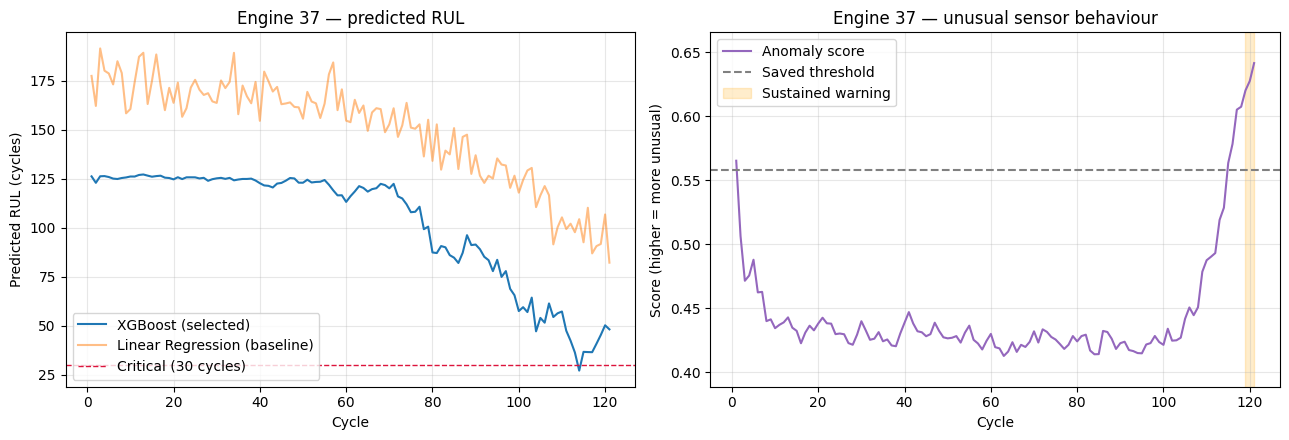

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(engine_scored["cycle"], engine_scored["predicted_rul"], label="XGBoost (selected)")
ax1.plot(engine_scored["cycle"], engine_scored["baseline_rul"], alpha=0.5, label="Linear Regression (baseline)")
ax1.axhline(pm.CRITICAL_RUL, color="crimson", linestyle="--", linewidth=1, label=f"Critical ({pm.CRITICAL_RUL} cycles)")
ax1.set(title=f"Engine {ENGINE_ID} — predicted RUL", xlabel="Cycle", ylabel="Predicted RUL (cycles)")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(engine_scored["cycle"], engine_scored["anomaly_score"], color="tab:purple", label="Anomaly score")
ax2.axhline(models.anomaly["threshold"], color="gray", linestyle="--", label="Saved threshold")
ax2.fill_between(engine_scored["cycle"], 0, 1, where=engine_scored["sustained_warning"],
                 transform=ax2.get_xaxis_transform(), color="orange", alpha=0.2, label="Sustained warning")
ax2.set(title=f"Engine {ENGINE_ID} — unusual sensor behaviour", xlabel="Cycle", ylabel="Score (higher = more unusual)")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Fleet view: which engines should be inspected first?

The planner has limited inspection capacity (01 — Business Understanding). All 100 engines are scored at their latest cycle and ranked by predicted RUL. The demo labels below are **illustrative settings, not a validated policy**:

| Column | Rule |
|---|---|
| `rul_status` | Critical if predicted RUL ≤ 30, Plan inspection if ≤ 60, otherwise Monitor |
| `anomaly_status` | Sustained unusual pattern / Isolated unusual readings (last 10 cycles) / Normal pattern |
| `suggested_action` | Inspect first if RUL is critical; otherwise *take a closer look* if a sustained warning is active |

The second rule follows the suggestion from 04 — Modeling ("predicted RUL ≤ X **or** a sustained warning") and the finding in 05 — Evaluation that 2 of the 3 severely late predictions had an active sustained warning.

In [9]:
fleet_scored = pm.score_engines(test_df, models)
fleet = pm.engine_summary(fleet_scored)

INSPECTION_SLOTS = 10
columns = ["priority", "unit", "last_cycle", "predicted_rul", "rul_status",
           "anomaly_status", "suggested_action"]
fleet[columns].head(INSPECTION_SLOTS).round(1)

,priority,unit,last_cycle,predicted_rul,rul_status,anomaly_status,suggested_action
0,1,76,205,6.4,Critical,Sustained unusual pattern,Inspect first
1,2,81,213,6.9,Critical,Sustained unusual pattern,Inspect first
2,3,34,203,7.1,Critical,Sustained unusual pattern,Inspect first
3,4,82,162,7.9,Critical,Sustained unusual pattern,Inspect first
4,5,68,187,9.1,Critical,Sustained unusual pattern,Inspect first
5,6,42,156,10.4,Critical,Sustained unusual pattern,Inspect first
6,7,20,184,10.9,Critical,Sustained unusual pattern,Inspect first
7,8,35,198,11.1,Critical,Sustained unusual pattern,Inspect first
8,9,31,196,12.6,Critical,Sustained unusual pattern,Inspect first
9,10,66,147,13.9,Critical,Sustained unusual pattern,Inspect first


In [10]:
print("Suggested actions across the fleet:")
print(fleet["suggested_action"].value_counts().to_string())

extra = fleet[(fleet["rul_status"] != "Critical") & fleet["sustained_warning"]]
print(f"\nEngines outside the critical RUL range with an active sustained warning: {len(extra)}")
print(extra[["unit", "predicted_rul", "consecutive_flags"]].round(1).to_string(index=False))

Suggested actions across the fleet:
suggested_action
Continue monitoring                            61
Inspect first                                  19
Take a closer look (unusual sensor pattern)    18
Schedule inspection                             2

Engines outside the critical RUL range with an active sustained warning: 18
 unit  predicted_rul  consecutive_flags
   53      30.200001                 19
   52      33.299999                 11
   90      33.599998                 28
   77      34.400002                 14
   40      34.500000                 51
   41      35.299999                  9
   58      41.799999                 11
    3      43.099998                 11
   38      45.099998                 35
   46      47.500000                 23
   17      47.700001                  7
   37      48.200001                  7
   62      51.099998                  5
   45      52.299999                  6
   93      57.000000                 63
   94      61.900002          

## 6. Check: same results as 05 — Evaluation

The deployment path must reproduce the evaluated results exactly. Otherwise the demo would show a model that behaves differently from the one that was evaluated.

In [11]:
ref_pred = pd.read_csv(pm.EVAL_OUTPUTS_DIR / "test_rul_predictions.csv").set_index("unit").sort_index()
ref_warn = pd.read_csv(pm.EVAL_OUTPUTS_DIR / "sustained_anomaly_warnings.csv")
mine = fleet.set_index("unit").sort_index()

rul_diff = np.abs(mine["predicted_rul"] - ref_pred["xgb_predicted_rul"]).max()
base_diff = np.abs(mine["baseline_rul"] - ref_pred["baseline_predicted_rul"]).max()
merged = fleet_scored.merge(ref_warn, on=["unit", "cycle"], suffixes=("", "_ref"))
score_diff = np.abs(merged["anomaly_score"] - merged["anomaly_score_ref"]).max()
warn_same = (merged["sustained_warning"] == merged["sustained_warning_ref"]).all()

print(f"Max difference, XGBoost RUL:   {rul_diff:.6f} cycles")
print(f"Max difference, baseline RUL:  {base_diff:.6f} cycles")
print(f"Max difference, anomaly score: {score_diff:.2e}")
print(f"Sustained warnings identical:  {warn_same}")

assert rul_diff < 1e-3 and base_diff < 1e-6 and score_diff < 1e-9 and warn_same
print("\nDeployment reproduces the 05 — Evaluation results.")

Max difference, XGBoost RUL:   0.000004 cycles
Max difference, baseline RUL:  0.000000 cycles
Max difference, anomaly score: 1.11e-16
Sustained warnings identical:  True

Deployment reproduces the 05 — Evaluation results.


## 7. A new engine record from a CSV file

In practice a new record would arrive as a file. `sample_input/new_engine_sample.csv` has the expected format: one row per cycle with the columns listed in section 2 (extra columns are ignored). It contains the first 110 cycles of validation engine 91, so it is a format example, not an unseen engine. The same validation step rejects records with missing columns, missing values, duplicated cycles, gaps in the cycle sequence, or a first cycle other than 1.

In [12]:
new_record = pd.read_csv(DEPLOY_DIR / "sample_input" / "new_engine_sample.csv")
new_now = pm.engine_summary(pm.score_engines(new_record, models)).iloc[0]

print(f"Engine {int(new_now['unit'])}, cycle {int(new_now['last_cycle'])}")
print("Predicted RUL:     ", pm.describe_rul(new_now["predicted_rul"]), f"-> {new_now['rul_status']}")
print("Anomaly status:    ", new_now["anomaly_status"])
print("Suggested action:  ", new_now["suggested_action"])

try:
    pm.validate_input(new_record.drop(columns=["sensor_4"]), models)
except ValueError as error:
    print("\nRejected record example ->", error)

Engine 91, cycle 110
Predicted RUL:      about 29 cycles -> Critical
Anomaly status:     Sustained unusual pattern
Suggested action:   Inspect first

Rejected record example -> Missing columns: ['sensor_4']


## 8. Save the demo output

In [13]:
OUTPUT_DIR = DEPLOY_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
fleet_out = fleet.merge(true_rul.rename("official_true_rul"), left_on="unit", right_index=True)
fleet_out.round(3).to_csv(OUTPUT_DIR / "fleet_inspection_status.csv", index=False)
print("Saved:", (OUTPUT_DIR / "fleet_inspection_status.csv").relative_to(pm.REPO_DIR))

Saved: 06_deployment/outputs/fleet_inspection_status.csv


## 9. Limitations

- **Simulated data.** FD001 has one operating condition and one fault mode; results may not transfer to real engines.
- **Late predictions remain.** On the test set, 3 of 25 critical engines were predicted more than 10 cycles late (engine 37: +27 cycles). The prediction is decision support, not an instruction.
- **Planning horizon.** The model was trained with RUL capped at 125 cycles. Above that it only indicates a healthy engine.
- **Anomaly ≠ fault.** Isolation Forest shows unusual sensor patterns compared with early, healthy cycles. FD001 has no labelled anomalies, so its precision cannot be measured.
- **Demo thresholds.** The 30 / 60 cycle levels and the combined rule are illustrative settings for this demo and have not been validated as a maintenance policy.
- **Human review.** Every suggested action is meant to be reviewed by a maintenance planner.